### REINFORCE, Actor-Critic
1. REINFORCE
- 에피소드 전체를 모은 뒤 Monte Carlo return 'G_t'를 사용해 정책을 업데이트
- 정책 경사의 기본 개념이 명료함. 분산이 크고 에피소드 종료까지 기다려야 함

2. Actor-Critic
- Actor는 정책 `π(a|s)`를 Critic은 `V(s)`를 학습
- TD 목표: `y_t = r_t + γ(1-d_t)V(s_{t+1})`
- Advantage
    - 내가 선택한 행동이 평소 기대했던 것보다 얼마나 좋았는가를 나타내는 값
    - V(s): 현재 상태에서 앞으로 얼마나 많은 보상을 받을 것으로 예상
    - Advantage A(s, a): 현재 상태에서 행동이 평균적인 기대보다 얼마나 좋은가?
        - 양수면 그 행동의 선택 확률을 높임
        - 음수면 그 행동의 선택 확률을 낮춤 임
    - `A_t ≈ y_t − V(s_t)`
```
    평소 예상 점수는 70점이었는데, 실제로 90점을 받음
        Advantage = 90 - 70 = +20
    예상 점수는 70점이었는데, 실제로 50점 바음
        Advantage = 50 - 70 = -20  
```
- Actor 손실 L_actor = −log π(a_t|s_t) · stop_gradient(A_t)
- Critic 손실 L_critic = (V(s_t)−y_t)^2        
    

# **1. A2C**
A2C(Advantage Actor-Critic)는 정책(Actor)과 가치함수(Critic)를 함께 학습하면서,
Advantage를 이용해 정책의 방향을 정하는 Actor-Critic 계열 알고리즘. A2C는 N개의 환경이 일정한 길이 T만큼 동시에 경험을 수집한 뒤, 그 경험을 합쳐 한 번에 신경망을 갱신함

### A2C의 배경
- 단일 환경에서 연속으로 수집한 경험은 비슷한 장면이 반복
- 환경 여러 개에서 서로 다른 상태를 경험하면 학습 배치가 다양해짐
- 한 스텝만 보지 않고 n-step return을 사용하면 조금 더 먼 미래의 보상을 반영함
- 동기식이므로 모든 환경이 모인 뒤 갱신해 업데이트 절차를 이해/재현하기 쉬움

$$
한\ 스텝\ TD: G_t^{(1)}=r_t+\gamma V(s_{t+1})
$$

$$
n-step\ Return: G_t^{(n)}=r_t+\gamma r_{t+1}+\cdots+\gamma^{n-1}r_{t+n-1}+\gamma^n V(s_{t+n})
$$

$$
Advantage: A_t=G_t^{(n)}-V(s_t)
$$

$$
전체\ 손실\ : L=-\mathbb E[\log\pi(a_t|s_t)\,\mathrm{stopgrad}(A_t)]+c_v\mathbb E[(V(s_t)-G_t^{(n)})^2]-c_e\mathbb E[H(\pi(\cdot|s_t))]
$$
> n-step의 n은 신경망 층 수가 아니라 앞으로 관찰한 보상 스텝 수임

```
r_0 = 1 : 첫 번째 행동 후 받은 보상
r_1 = 1 : 두 번째 행동 후 받은 보상
r_2 = 1 : 세 번째 행동 후 받은 보상
γ = 0.9 : 미래 보상에 적용하는 할인율
V(s_3) = 5 : 세 번째 행동 후 상태에서 앞으로 받을 것으로 예산되는 보상
V(s_0) = 4 : 처음 상태에서 앞으로 받을 것으로 예상되는 보상
```

문제
1. AI가 3번의 행동으로 실제 받은 보상에 합계는 얼마일까?
    - 1 + 1 + 1 = 3
2. 미래 보상에 할인율을 적용하여 계산한 3-step Return은 얼마?
    - G₀⁽³⁾ = r₀ + γ r₁ + γ² r₂ + γ³ V(s₃)
    = 1 + 0.9×1 + 0.9²×1 + 0.9³×5
    = 1 + 0.9 + 0.81 + 0.729×5
    = 2.71 + 3.645
    = 6.355

    - 실제로 받은 보상은 3점이지만, 3번  행동한 이후의 미래 예상 가치까지 포함하고 할인율을 적용했기 때문에 6.355가 나옴

3. 처음 예상했던 가치와 비교한 Advantage는 얼마?
    - Advantage는 처음 예상했던 가치와 새롭게 계산한 목표 가치의 차이
        - Critic은 현재 상태의 가치를 4점이라고 예상
        - 3번 행동한 경험과 미래 예상 가치를 이용해 계산한 값은 6.355
        - A₀ = G₀⁽³⁾ − V(s₀)
        = 6.355 − 4
        = 2.355

4. 위 결과처럼 Advantage가 양수라는 것은 어떤 의미?
    - 처음 예상헀던 가치보다 새롭게 계산한 목표 가치가 2.355점 높다는 의미
    - Actor는 처음 상태 s0에서 선택했던 행동의 확률을 높이는 방향으로 학습

In [2]:
gamma = 0.9
rewards = [1.0, 1.0, 1.0]
bootstrap_value = 5.0
running = bootstrap_value

for r in reversed(rewards):
    running = r + gamma * running
print('3-step return: ', round(running, 3))
print('advantage: ', round(running - 4.0, 3))

3-step return:  6.355
advantage:  2.355


In [3]:
import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

In [4]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [5]:
class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1)

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

logits: torch.Size([4, 2]) values: torch.Size([4])


1. 환경 N개를 만들고 상태를 모음
2. T번 반복하면서 같은 정책으로 각 환경의 행동을 선택
3. 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피를 저장
4. 각 환경이 종료되면 다음 에피소드로 리셋. 단, 종료전 마지막 관측에서 계산한 부트스트랩 가치를 보존
5. 역순으로  n-step Return을 계산
6. Actor/Critic/Entropy 손실을 합산하고 optimizer.step()을 호출

Actor logits:  torch.Size([1, 2]) Critic V(s):  torch.Size([1])


In [ ]:
# # 내가 한 거
# ac_demo = DiscreteActorCritic().to(DEVICE)
# state_demo = torch.tensor([[0.0, 0.1, 0.02, -0.03]], dtype=torch.float32, device=DEVICE)
# lg, val = ac_demo(state_demo)
# print('Actor logits: ', lg.shape, 'Critic V(s): ', val.shape)


# import time
# import pandas as pd
# from torch import nn, optim

# # episodes: 학습할 에피소드 수
# # seed: 난수 생성의 기준값
# # gamma: 미래 보상의 할인율
# # lr: 신경망 학습률
# # hidden: 은닉층의 뉴런 수
# # max_steps: 한 에피소드에서 허용하는 최대 행동 횟수
# # critic_coef: Critic 손실의 가중치
# # entropy_coef: 탐색을 장려하는 엔트로피 보너스의 가중치
# # print_every: 학습 결과를 출력하는 간격
# def train_actor_critic(episodes=500, seed=2026, gamma=0.99, lr=3e-4, hidden=128, max_steps=500, critic_coef=0.5, entropy_coef=0.0, print_every=50):
#     env = gym.make('CartPole-v1')
#     env.action_space.seed(seed) # 행동 공간의 난수 고정
#     model = DiscreteActorCritic(4, 2, hidden=hidden).to(DEVICE) # 입력4개, 행동 2개인 Actor-Critic 모델 생성
#     optimizer = torch.optim.Adam(model.parameters(), lr=lr) # Adam 옵티마이저 설정
#     scores, lengths, actor_losses, critic_losses, entropies = [], [], [], [], [] # 학습 결과 저장
#     start = time.time() # 학습 시작 시간
#     actor_loss = []
#     critic_loss = []

#     for ep in range(episodes):
#         state, _ = env.reset(seed=seed+ep) # 환경 초기화
#         score, steps = 0.0, 0 # 에피소드 보상 및 행동 횟수 초기화
#         ep_actor, ep_critic, ep_entropy = [], [], [] # 에피소드별 손실 및 엔트로피 저장

#         for t in range(max_steps):
#             x = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0) # 상태를 텐서로 변환
#             logits, value = model(x) # Actor의 행동 점수와 Critic의 상태 가치 예측
#             dist = Categorical(logits=logits) # 행동 확률 분포 생성
#             action = dist.sample() # 행동 확률에 따라 행동 선택

#             next_state, reward, terminated, truncated, _ = env.step(int(action.item())) # 행동 실행 후 다음 상태와 보상 확인

#             # TD Target 계산
#             # with torch.no_grad():
#             #     nx = torch.as_tensor(next_state, dtype=torch.float32, device=DEVICE).unsqueeze(0) # 다음 상태를 텐서로 변환
#             #     _, next_value = model(nx) # 다음 상태의 가치 예측
#             #     td_target = torch.as_tensor([reward], dtype=torch.float32, device=DEVICE) + gamma * (1.0 - float(terminated)) * next_value # 보상 + 할인된 다음 상태 가치

#             delta = td_target - value # TD 오차 계산
#             actor_loss.append(-(dist.log_prob(action) * delta.detach()).mean()) # Actor 손실 계산 (TD 오차로 행동 정책 업데이트)
#             critic_loss.append(F.mse_loss(value, td_target)) # Critic 손실 계산 (예측 가치와 TD Target의 차이)
#             entropy = dist.entropy().mean() # 행동 확률 분포의 엔트로피 계산
#             loss = actor_loss[t] + critic_coef * critic_loss[t] - entropy_coef * entropy # 전체 손실 계산

#             score += float(reward) # 보상 누적
#             steps += 1 # 행동 횟수 증가
#             state = next_state # 다음 상태로 이동
#             ep_actor.append(float(actor_loss[t])) # Actor 손실 저장
#             ep_critic.append(float(critic_loss[t])) # Critic 손실 저장
#             ep_entropy.append(float(entropy.item())) # 엔트로피 저장

#             if terminated or truncated: # 착륙, 추락 또는 제한 조건에 도달하면 종료
#                 break

#         scores.append(score) # 에피소드 총보상 저장
#         lengths.append(steps) # 에피소드 행동 횟수 저장
#         entropies.append(float(np.mean(ep_entropy))) # 평균 엔트로피 저장

#         if print_every and (ep+1) % print_every == 0: # 지정된 에피소드 간격마다 결과 출력
#             recent = np.mean(scores[-min(50,len(scores)):]) # 최근 최대 50회 평균 보상
#             print(f"Actor-Critic {ep+1:4d}/{episodes} | 최근 50회 평균 {recent:8.2f} | "
#                 f"이번 보상 {score:8.2f} | {time.time()-start:.0f}s")
    
#     optimizer.zero_grad() # 이전 기울기 초기화
#     loss.backward() # 역전파로 기울기 계산
#     nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # 기울기 폭발 방지
#     optimizer.step() # 모델 가중치 업데이트
    
#     env.close() # 환경 종료
#     history = pd.DataFrame({ # 학습 결과를 DataFrame으로 변환
#         "episode": np.arange(1, episodes+1), "reward": scores,
#         "steps": lengths, "actor_loss": actor_losses,
#         "critic_loss": critic_losses, "entropy": entropies,
#     })
#     return model, history # 학습된 모델과 학습 기록 반환

A2C   100/1500 | 최근 20 에피소드 평균   23.70 | actor   0.258 | critic   19.633 | entropy 0.672 | 0s
A2C   200/1500 | 최근 20 에피소드 평균   36.65 | actor   0.305 | critic   27.889 | entropy 0.663 | 1s
A2C   300/1500 | 최근 20 에피소드 평균   34.90 | actor  -0.515 | critic   52.273 | entropy 0.638 | 1s
A2C   400/1500 | 최근 20 에피소드 평균   48.00 | actor   1.213 | critic    6.894 | entropy 0.621 | 2s
A2C   500/1500 | 최근 20 에피소드 평균   65.15 | actor   0.577 | critic   65.114 | entropy 0.605 | 2s
A2C   600/1500 | 최근 20 에피소드 평균   45.45 | actor   1.016 | critic    5.180 | entropy 0.626 | 3s
A2C   700/1500 | 최근 20 에피소드 평균   82.25 | actor   0.112 | critic  106.499 | entropy 0.659 | 3s
A2C   800/1500 | 최근 20 에피소드 평균   93.20 | actor   0.601 | critic   33.056 | entropy 0.656 | 3s
A2C   900/1500 | 최근 20 에피소드 평균   75.05 | actor  -0.615 | critic   72.644 | entropy 0.597 | 4s
A2C  1000/1500 | 최근 20 에피소드 평균   81.50 | actor  -0.213 | critic    2.076 | entropy 0.600 | 4s
A2C  1100/1500 | 최근 20 에피소드 평균   86.45 | actor   0.045 | cri

c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 52572 (\N{HANGUL SYLLABLE COE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44540 (\N{HANGUL SYLLABLE GEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\heeseung\13_MultiModal\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sa

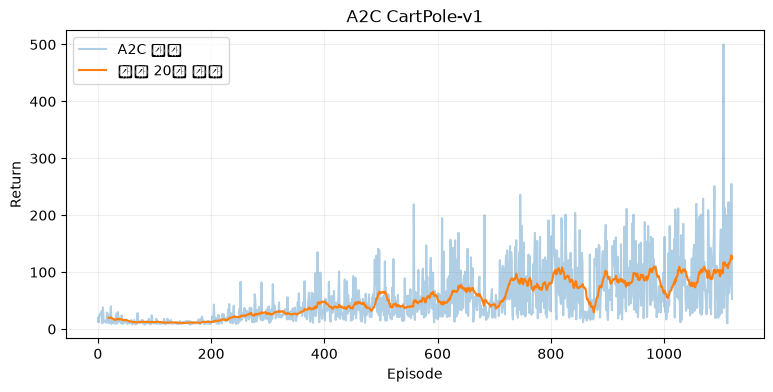

In [ ]:
# # 클로드
# def train_a2c(updates=1500, n_envs=8, n_steps=5, seed=2026, gamma=0.99, lr=7e-4,
#               hidden=128, critic_coef=0.5, entropy_coef=0.01, print_every=100):
#     # updates: 신경망을 갱신할 횟수
#     # n_envs: 동시에 돌릴 환경 개수 (N)
#     # n_steps: 갱신 전에 환경마다 모을 스텝 수 (T)

#     # [1단계] 환경 N개를 만들고 첫 상태를 모음
#     envs = [gym.make('CartPole-v1') for _ in range(n_envs)]
#     states = np.array([env.reset(seed=seed + i)[0] for i, env in enumerate(envs)])  # (N, 4)

#     model = DiscreteActorCritic(4, 2, hidden=hidden).to(DEVICE)
#     optimizer = torch.optim.Adam(model.parameters(), lr=lr)

#     ep_scores = np.zeros(n_envs)   # 환경별로 진행 중인 에피소드 점수
#     finished_scores = []           # 끝난 에피소드들의 최종 점수
#     start = time.time()

#     for update in range(updates):
#         # [3단계] 저장할 재료 리스트 (매 갱신마다 비움)
#         values, log_probs, entropies, rewards, masks = [], [], [], [], []

#         # [2단계] T스텝 동안 N개 환경을 같은 정책으로 동시에 진행
#         for t in range(n_steps):
#             x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)  # (N, 4)
#             logits, value = model(x)              # logits: (N, 2), value: (N,)
#             dist = Categorical(logits=logits)
#             actions = dist.sample()               # (N,) 환경마다 행동 하나씩

#             # 학습에 쓸 값은 텐서 그대로 저장 (.item() 금지: 기울기 정보가 사라짐)
#             values.append(value)
#             log_probs.append(dist.log_prob(actions))
#             entropies.append(dist.entropy())

#             step_rewards, step_masks, next_states = [], [], []
#             for i, env in enumerate(envs):
#                 ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
#                 ep_scores[i] += r
#                 done = terminated or truncated

#                 # [4단계] 끝난 환경은 점수를 기록하고 리셋해서 다음 에피소드로 이어감
#                 if done:
#                     finished_scores.append(ep_scores[i])
#                     ep_scores[i] = 0.0
#                     ns, _ = env.reset()

#                 step_rewards.append(r)
#                 step_masks.append(0.0 if done else 1.0)  # 끝났으면 미래 가치를 이어붙이지 않음
#                 next_states.append(ns)

#             # 보상, 마스크는 정답지 역할이라 기울기가 필요 없음
#             rewards.append(torch.as_tensor(step_rewards, dtype=torch.float32, device=DEVICE))  # (N,)
#             masks.append(torch.as_tensor(step_masks, dtype=torch.float32, device=DEVICE))      # (N,)
#             states = np.array(next_states)

#         # [5단계] 역순으로 n-step Return 계산
#         with torch.no_grad():  # 부트스트랩 값은 정답지의 일부라서 기울기 차단
#             _, running = model(torch.as_tensor(states, dtype=torch.float32, device=DEVICE))  # V(s_T), (N,)

#         returns = [None] * n_steps
#         for t in reversed(range(n_steps)):
#             running = rewards[t] + gamma * masks[t] * running  # G_t = r_t + γ·G_{t+1}
#             returns[t] = running

#         # 리스트를 (T, N) 텐서로 합침
#         values = torch.stack(values)
#         log_probs = torch.stack(log_probs)
#         entropies = torch.stack(entropies)
#         returns = torch.stack(returns)

#         # [6단계] 손실 계산 후 한 번만 업데이트
#         advantages = returns - values                                 # A_t = G_t - V(s_t)
#         actor_loss = -(log_probs * advantages.detach()).mean()        # stopgrad(A)는 detach
#         critic_loss = F.mse_loss(values, returns)                     # V를 G에 가깝게
#         entropy = entropies.mean()                                    # 탐험 보너스
#         loss = actor_loss + critic_coef * critic_loss - entropy_coef * entropy

#         optimizer.zero_grad()
#         loss.backward()
#         nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
#         optimizer.step()

#         if print_every and (update + 1) % print_every == 0 and finished_scores:
#             recent = np.mean(finished_scores[-20:])
#             print(f"A2C {update+1:5d}/{updates} | 최근 20 에피소드 평균 {recent:7.2f} | "
#                 f"actor {actor_loss.item():7.3f} | critic {critic_loss.item():8.3f} | "
#                 f"entropy {entropy.item():.3f} | {time.time()-start:.0f}s")

#     for env in envs:
#         env.close()

#     history = pd.DataFrame({"episode": np.arange(1, len(finished_scores) + 1),
#                             "reward": finished_scores})
#     return model, history


# a2c_model, a2c_history = train_a2c()
# a2c_scores = a2c_history['reward'].tolist()
# plt.figure(figsize=(9, 4))
# plt.plot(a2c_scores, alpha=0.35, label='A2C 보상')
# if len(a2c_scores) >= 20:
#     ma = np.convolve(a2c_scores, np.ones(20)/20, mode='valid')
#     plt.plot(np.arange(19, len(a2c_scores)), ma, label='최근 20회 평균')
# plt.xlabel('Episode'); plt.ylabel('Return'); plt.title('A2C CartPole-v1')
# plt.legend(); plt.grid(alpha=0.2); plt.show()

In [15]:
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [16]:
def make_envs(n=4, name="CartPole-v1", seed=2026):
    envs = [gym.make(name) for _ in range(n)]
    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)
    return envs, np.asanyarray(states, dtype=np.float32)

In [30]:
# 강사님
# 4개의 게임을 각각 5스텝씩 실행하고, 총 20개의 경험을 모아 한 번 학습하는 과정을 300회 반복
# 300 * 4 * 5 = 6000(총 환경 스텝 수)
def train_a2c(updates=3000, n_envs=4, rollout_steps=5, seed=2026, gamma=0.99, lr=7e-4, value_coef=0.5, entropy_coef=0.01, print_every=50):
    set_seed(seed)
    
    # envs = [환경0, 환경1, 환경2, 환경3]
    # states = [환경0의 현재 상태, 환경1의 현재 상태 .. ]
    # 상태: 카트위치, 속도, 막대기 기울기, 각속도
    envs, states = make_envs(n_envs, seed=seed)
    model = DiscreteActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr = lr)

    # 각 환경에서 현재 진행 중인 에피소드의 누적 보상을 저장
    episode_scores = np.zeros(n_envs, dtype=np.float64)
    completed = [] # 종료했을 때 loss 기록
    history = []

    try:
        for update in range(1, updates + 1):
            # logps: 실제 선택한 행동의 로그 확률
            # vals: Critic이 예측한 현재 상태 가치
            # bootstraps: 다음 상태에서의 예상 가치
            # boundaries: 에피소드 종료 여부
            logps, vals, rewards, bootstraps = [], [], [], []
            boundaries, entropies = [], []

            for t in range(rollout_steps):
                x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)
                logits, value = model(x)
                dist = Categorical(logits=logits)
                actions = dist.sample()
                logps.append(dist.log_prob(actions))
                vals.append(value)
                entropies.append(dist.entropy())


                next_states, rs, bs, ends = [], [], [], []

                for i, env in enumerate(envs):

                    # ns: 다음 상태
                    ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
                    episode_scores[i] += float(r)

                    # 두 종료 조건 중 하나라도 참이면 현재 에피소드가 끝났다고 판단
                    boundary = bool(terminated or truncated)

                    # rs: 즉시 보상
                    rs.append(float(r))

                    # ends: 에피소드 경계 여부
                    ends.append(boundary)

                    # bs: 종료 직전 다음 상태와 실제 종료 여부
                    # ns를 저장하는 이유는 truncated=True일 때 다음 상태 가치를 이용해 Bootstrap을 계산해야 하기 때문
                    bs.append((ns, bool(terminated)))

                    if boundary:
                        # 환경이 종료되었다면
                        # 1. 종료된 에피소드의 최종 보상을 저장
                        # 2. 해당 환경의 누적 보상을 0으로 초기화
                        # 3. env.reset()으로 새로운 에피소드를 시작
                        completed.append(float(episode_scores[i]))
                        episode_scores[i] = 0.0
                        ns, _ = env.reset()

                        # ns는 종료되지 않았다면 해동 후의 다음 상태, 종료되었다면 새로 초기화한 상태가 저장됨
                    next_states.append(ns)

                # Bootstrap
                # 아직 직접 경험하지 않은 미래의 보상을 Critic이 예측한 가치로 대신 게산하는 방법
                # 5스텝까지만  진행했지만 게임을 끝나지 않음 > 5스텝 이후에 받을 보상은 아직 알 수 없음
                # Critic 이 다음 상태의 가치를 10점이라도 예측했다면, 그 값ㅇ르 미래 보상의 추정치로 이용
                # bs [(환경0의 다음 상태, False), (환경1의 다음 상태, True) ...]
                bootstrap_x = torch.as_tensor(
                    np.asanyarray([item[0] for item in bs], dtype=np.float32), device=DEVICE
                )

                with torch.no_grad():
                    _, bootstrap_values = model(bootstrap_x)
                    """
                    bootstrap_value = [12.0, 8.0, 15.0, 20.0]
                    terminated=True > 1
                    terminated=False > 0
                    환경 0, 다음 상태 가치 12.0, terminated False > 최종 Bootstrap 12
                    환경 1, 다음 상태 가치 8.0, terminated True > 최종 Bootstrap 0
                    ...
                    """
                    true_terminal = torch.tensor(
                        [float(item[1]) for item in bs], device=DEVICE
                    )
                    bootstrap_values = bootstrap_values * (1.0 - true_terminal)

                rewards.append(torch.tensor(rs, dtype=torch.float32, device=DEVICE))
                bootstraps.append(bootstrap_values)
                boundaries.append(torch.tensor(ends, dtype=torch.bool, device=DEVICE))
                states = np.asanyarray(next_states, dtype=np.float32)

            # 5스텝 동안 얻은 보상과 미래 예상 가치를 역순으로 합산
            # 마지막 스텝의 미래 가치를 먼저 알아야 이전 스탭의 Return을 계산할 수 있음
            """
                rewards = [1, 1, 1]
                gamma = 0.9
                next_value = 5

                역순 계산
                마지막 Bootstrap은 5
                t=2 > 1 + 0.9 * 5
                t=1 > 1 + 0.9 * 5.5
                t=0 > 1 + 0.9 * 5.95
            """
            running = bootstraps[-1]
            targets = [None] * rollout_steps
            for t in reversed(range(rollout_steps)):

                # 환경0이 세 번째 스텝에서 종료되고 네 번째 스텝부터 새로운 게임이 시작된다면
                # 이전 게임의 Return에 새로운 게임의 보상을 더하면 안됨
                running = torch.where(boundaries[t], bootstraps[t], running)
                running = rewards[t] + gamma * running
                targets[t] = running

            target_t = torch.stack(targets).detach()
            value_t = torch.stack(vals)
            logp_t = torch.stack(logps)
            entropy_t = torch.stack(entropies)
            advantage = target_t - value_t

            actor_loss = -(logp_t * advantage.detach()).mean()
            critic_loss = advantage.square().mean()
            entropy_bonus = entropy_t.mean()
            loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            recent = float(np.mean(completed[-20:])) if completed else np.nan
            history.append({'update': update, 'episodes_done': len(completed),
                            'recent20_reward': recent, 'loss': float(loss.item())})
            if update % print_every == 0:
                print(f'A2C update {update:4d}/{updates} | 종료 에피소드 {len(completed):4d} '
                    f'| 최근20 평균 {recent:7.2f}')

    finally:
        for env in envs:
            env.close()
    return model, pd.DataFrame(history), completed

In [31]:
a2c_model, a2c_hist, a2c_scores = train_a2c(updates=3000, n_envs=4, rollout_steps=5, seed=2026, print_every=50)

A2C update   50/3000 | 종료 에피소드   38 | 최근20 평균   25.05
A2C update  100/3000 | 종료 에피소드   76 | 최근20 평균   30.90
A2C update  150/3000 | 종료 에피소드  111 | 최근20 평균   28.55
A2C update  200/3000 | 종료 에피소드  147 | 최근20 평균   27.40
A2C update  250/3000 | 종료 에피소드  182 | 최근20 평균   29.45
A2C update  300/3000 | 종료 에피소드  208 | 최근20 평균   39.95
A2C update  350/3000 | 종료 에피소드  240 | 최근20 평균   30.65
A2C update  400/3000 | 종료 에피소드  267 | 최근20 평균   34.75
A2C update  450/3000 | 종료 에피소드  292 | 최근20 평균   41.65
A2C update  500/3000 | 종료 에피소드  314 | 최근20 평균   45.35
A2C update  550/3000 | 종료 에피소드  334 | 최근20 평균   49.10
A2C update  600/3000 | 종료 에피소드  357 | 최근20 평균   47.00
A2C update  650/3000 | 종료 에피소드  385 | 최근20 평균   32.75
A2C update  700/3000 | 종료 에피소드  405 | 최근20 평균   43.35
A2C update  750/3000 | 종료 에피소드  422 | 최근20 평균   62.55
A2C update  800/3000 | 종료 에피소드  438 | 최근20 평균   59.95
A2C update  850/3000 | 종료 에피소드  463 | 최근20 평균   38.25
A2C update  900/3000 | 종료 에피소드  487 | 최근20 평균   41.35
A2C update  950/3000 | 종료 에피

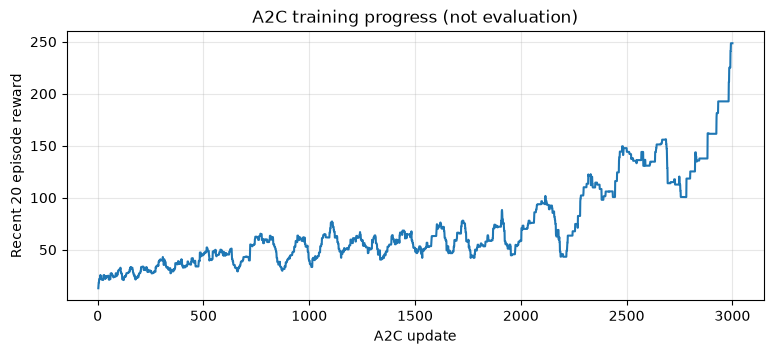

In [32]:
plt.figure(figsize=(9, 3.5))
plt.plot(a2c_hist['update'], a2c_hist['recent20_reward'])
plt.xlabel('A2C update')
plt.ylabel('Recent 20 episode reward')
plt.title('A2C training progress (not evaluation)')
plt.grid(alpha=0.3)
plt.show()